In [1]:
import pandas as pd
import numpy as np

In [2]:
import os
csv_path = 'data/Crop_recommendation.csv' if os.path.exists('data/Crop_recommendation.csv') else 'Crop_recommendation.csv'
crop = pd.read_csv(csv_path)


In [3]:
crop.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
crop.shape

(2108, 8)

In [5]:
crop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2108 entries, 0 to 2107
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2108 non-null   int64  
 1   P            2108 non-null   int64  
 2   K            2108 non-null   int64  
 3   temperature  2108 non-null   float64
 4   humidity     2108 non-null   float64
 5   ph           2108 non-null   float64
 6   rainfall     2108 non-null   float64
 7   label        2108 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 131.9+ KB


In [6]:
crop.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [7]:
crop.duplicated().sum()

0

In [8]:
crop.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2108.000000,2108.000000,2108.000000,2108.000000,2108.000000,2108.000000,2108.000000
mean,48.370019,54.912713,48.068311,25.482624,70.574794,6.474741,106.902333
std,36.082523,32.800340,51.736005,5.128576,22.305706,0.788712,53.563750
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,21.135457
25%,20.000000,31.000000,20.000000,22.607538,59.300635,5.950473,67.054317
50%,36.000000,53.000000,30.000000,25.396502,80.032998,6.431478,97.490356
75%,81.000000,69.000000,47.000000,28.303295,88.183031,6.943050,129.642931
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [9]:
numeric_crop = crop.select_dtypes(include=[np.number])

In [10]:
corr_matrix = numeric_crop.corr()

<Axes: >

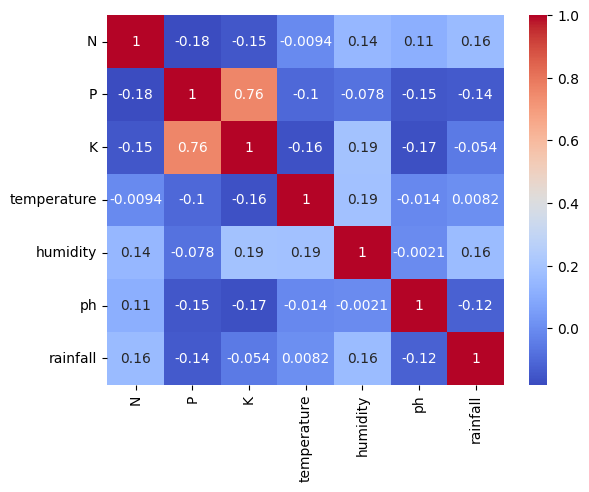

In [11]:
import seaborn as sns
sns.heatmap(corr_matrix, annot=True, cbar=True, cmap='coolwarm')

In [12]:
crop.label.value_counts()

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
muskmelon        8
Name: count, dtype: int64

In [13]:
crop['label'].unique().size

22

C:\Users\yusuf\AppData\Local\Temp\ipykernel_17252\1018874597.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crop['P'])


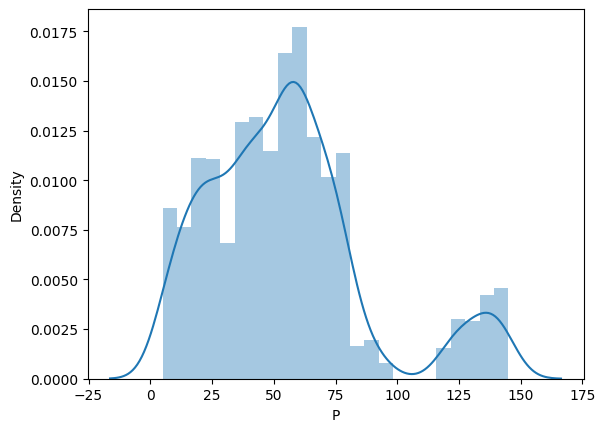

In [14]:
import matplotlib.pyplot as plt
sns.distplot(crop['P'])
plt.show()

C:\Users\yusuf\AppData\Local\Temp\ipykernel_17252\2091051290.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crop['N'])


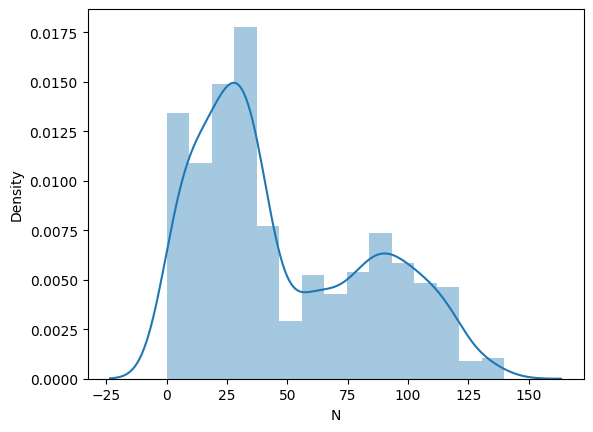

In [15]:
import matplotlib.pyplot as plt
sns.distplot(crop['N'])
plt.show()

In [16]:
crop.label.unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [17]:
crop_dict={
    'rice': 1,
    'maize': 2,
    'jute': 3,
    'cotton': 4,
    'coconut': 5,
    'papaya': 6,
    'orange': 7,
    'apple': 8,
    'muskmelon': 9,
    'watermelon': 10,
    'grapes': 11,
    'mango': 12,
    'banana': 13,
    'pomegranate': 14,
    'lentil': 15,
    'blackgram': 16,
    'mungbean': 17,
    'mothbeans': 18,
    'pigeonpeas': 19,
    'kidneybeans': 20,
    'chickpea': 21,
    'coffee': 22
}

crop['label'] = crop['label'].map(crop_dict)

In [18]:
crop.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,1
1,85,58,41,21.770462,80.319644,7.038096,226.655537,1
2,60,55,44,23.004459,82.320763,7.840207,263.964248,1
3,74,35,40,26.491096,80.158363,6.980401,242.864034,1
4,78,42,42,20.130175,81.604873,7.628473,262.717340,1


In [19]:
crop.label.unique()

array([ 1,  2, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,
        6,  5,  4,  3, 22], dtype=int64)

In [20]:
crop.label.value_counts()

label
1     100
2     100
3     100
4     100
5     100
6     100
7     100
8     100
10    100
11    100
12    100
13    100
14    100
15    100
16    100
17    100
18    100
19    100
20    100
21    100
22    100
9       8
Name: count, dtype: int64

In [21]:
X=crop.drop('label', axis = 1)
y=crop['label']

In [22]:
X.head()

,N,P,K,temperature,humidity,ph,rainfall
0,90,42,43,20.879744,82.002744,6.502985,202.935536
1,85,58,41,21.770462,80.319644,7.038096,226.655537
2,60,55,44,23.004459,82.320763,7.840207,263.964248
3,74,35,40,26.491096,80.158363,6.980401,242.864034
4,78,42,42,20.130175,81.604873,7.628473,262.717340


In [23]:
y.head()

0    1
1    1
2    1
3    1
4    1
Name: label, dtype: int64

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [25]:
X_train.shape

(1686, 7)

In [26]:
from sklearn.preprocessing import MinMaxScaler
mx = MinMaxScaler()
X_train = mx.fit_transform(X_train)
X_test = mx.transform(X_test)

In [27]:
X_train

array([[0.1       , 0.14285714, 0.175     , ..., 0.8951026 , 0.45147231,
        0.29279552],
       [0.21428571, 0.25714286, 0.05      , ..., 0.34899609, 0.37017406,
        0.10541678],
       [0.11428571, 0.51428571, 0.085     , ..., 0.24946059, 0.47733994,
        0.28132069],
       ...,
       [0.07857143, 0.22142857, 0.13      , ..., 0.4377689 , 0.46198144,
        0.28027451],
       [0.07857143, 0.85      , 0.995     , ..., 0.76779275, 0.44420505,
        0.17553536],
       [0.22857143, 0.52142857, 0.085     , ..., 0.5611593 , 0.54465022,
        0.11023658]])

In [28]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(X_train)
X_train = sc.transform(X_train)
X_test=sc.transform(X_test)

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score

In [30]:
models = {
    'LogisticRegression': LogisticRegression(),
    'GaussianNB':GaussianNB(),
    'SVC':SVC(),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'DecisionTreeClassifier':DecisionTreeClassifier(),
    'ExtraTreeClassifier':ExtraTreeClassifier(),
    'RandomForestClassifier':RandomForestClassifier(),
    'BaggingClassifier':BaggingClassifier(),
    'GradientBoostingClassifier':GradientBoostingClassifier(),
    'AdaBoostClassifier':AdaBoostClassifier()
}

In [31]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score = accuracy_score(y_test, y_pred)
    print(f"{name} model with accuracy: {score}")

LogisticRegression model with accuracy: 0.9478672985781991
GaussianNB model with accuracy: 0.995260663507109
SVC model with accuracy: 0.957345971563981
KNeighborsClassifier model with accuracy: 0.9502369668246445
DecisionTreeClassifier model with accuracy: 0.9786729857819905
ExtraTreeClassifier model with accuracy: 0.8933649289099526
RandomForestClassifier model with accuracy: 0.990521327014218
BaggingClassifier model with accuracy: 0.990521327014218
GradientBoostingClassifier model with accuracy: 0.981042654028436


c:\Users\yusuf\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoostClassifier model with accuracy: 0.12796208530805686


In [32]:
randclf = RandomForestClassifier()
randclf.fit(X_train, y_train)
y_pred = randclf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred) * 100
print(f"RandomForestClassifier accuracy: {accuracy:.2f}%")


RandomForestClassifier accuracy: 99.29%


In [33]:
crop.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [34]:
def recommendation(N,P,K,temperature,humidity,ph,rainfall):
    features = np.array([[N,P,K,temperature,humidity,ph,rainfall]])
    mx_features = mx.transform(features)
    sc_mx_features = sc.transform(mx_features)
    prediction = randclf.predict(sc_mx_features).reshape(1,-1)
    return prediction[0]


In [35]:
crop.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,1
1,85,58,41,21.770462,80.319644,7.038096,226.655537,1
2,60,55,44,23.004459,82.320763,7.840207,263.964248,1
3,74,35,40,26.491096,80.158363,6.980401,242.864034,1
4,78,42,42,20.130175,81.604873,7.628473,262.717340,1


In [36]:
N=90
P= 42
K= 43
temperature= 20.879744
humidity=82.002744
ph=6.502985
rainfall=202.935536

predict = recommendation(N,P,K,temperature,humidity,ph,rainfall)

In [37]:
predict

array([6], dtype=int64)

In [38]:
import pickle
pickle.dump(randclf, open('model.pkl', 'wb'))
pickle.dump(mx, open('minmaxscaler.pkl', 'wb'))
pickle.dump(sc, open('standscaler.pkl', 'wb'))